<a href="https://colab.research.google.com/github/IAMIOT1/h-c-m-y-/blob/main/h%E1%BB%8Dc_kh%C3%B4ng_gi%C3%A1m_s%C3%A1t.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PHẦN 1: TẢI DỮ LIỆU & TỔNG HỢP VECTOR ĐẶC TRƯNG

In [2]:
import pandas as pd
import numpy as np
import os
from sklearn.preprocessing import StandardScaler

# ==========================================
# 0. KẾT NỐI VỚI GOOGLE DRIVE TRÊN COLAB
# ==========================================
from google.colab import drive
drive.mount('/content/drive')

# Định nghĩa đường dẫn Drive
folder_path = '/content/drive/MyDrive/kiemtrahocmay/'

# ==========================================
# 1. LOAD DỮ LIỆU GỐC
# ==========================================
customer = pd.read_csv(os.path.join(folder_path, "1.Data_Customer.csv"))
customer.columns = customer.columns.str.strip().str.upper()

trans = pd.read_csv(os.path.join(folder_path, "2.Data_MyVIB_Transaction.csv"))
deposit = pd.read_csv(os.path.join(folder_path, "4.Data_Deposit.csv"))
lending = pd.read_excel(os.path.join(folder_path, "5.Data_Lending.xlsx"))

trans.columns = trans.columns.str.strip().str.upper()
deposit.columns = deposit.columns.str.strip().str.upper()
lending.columns = lending.columns.str.strip().str.upper()

# Tổng hợp các chỉ số tài chính cơ bản cho khách hàng
trans_agg = trans.groupby("CUSTOMER_NUMBER").agg(
    TRANS_SUM=("TRANS_AMOUNT", "sum"),
    TRANS_MEAN=("TRANS_AMOUNT", "mean"),
    TRANS_COUNT=("TRANS_AMOUNT", "count")
).reset_index()

deposit_agg = deposit.groupby("CUSTOMER_NUMBER").agg(
    CA_BALANCE_MEAN=("AVG_CA_BALANCE", "mean"),
    TD_BALANCE_MEAN=("AVG_TD_BALANCE", "mean")
).reset_index()

lending_agg = lending.groupby("CUSTOMER_NUMBER").agg(
    LOAN_AMOUNT_MEAN=("AVG_LOAN_AMOUNT", "mean")
).reset_index()

# Merge về bảng customer chung
df_cluster = customer[["CUSTOMER_NUMBER"]].copy()
df_cluster = df_cluster.merge(trans_agg, on="CUSTOMER_NUMBER", how="left")
df_cluster = df_cluster.merge(deposit_agg, on="CUSTOMER_NUMBER", how="left")
df_cluster = df_cluster.merge(lending_agg, on="CUSTOMER_NUMBER", how="left")
df_cluster.fillna(0, inplace=True)

print("Đã tổng hợp dữ liệu thành công! Shape:", df_cluster.shape)
print(df_cluster.head())

Mounted at /content/drive


/tmp/ipykernel_3137/3355826739.py:18: DtypeWarning: Columns (5,6,7,8) have mixed types. Specify dtype option on import or set low_memory=False.
  customer = pd.read_csv(os.path.join(folder_path, "1.Data_Customer.csv"))
/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)


Đã tổng hợp dữ liệu thành công! Shape: (290223, 7)
   CUSTOMER_NUMBER   TRANS_SUM    TRANS_MEAN  TRANS_COUNT  CA_BALANCE_MEAN  \
0           639362  21231000.0  1.633154e+06         13.0     1.653585e+06   
1           452440         0.0  0.000000e+00          0.0     1.336710e+05   
2           326290  86799392.0  1.846796e+06         47.0     3.068100e+06   
3            20802         0.0  0.000000e+00          0.0     0.000000e+00   
4           114244         0.0  0.000000e+00          0.0     1.971582e+05   

   TD_BALANCE_MEAN  LOAN_AMOUNT_MEAN  
0              0.0               0.0  
1              0.0               0.0  
2              0.0               0.0  
3              0.0               0.0  
4              0.0       295312500.0  


PHẦN 2: CHUẨN HÓA DỮ LIỆU (FEATURE SCALING)

In [3]:
# Chọn các cột đặc trưng tài chính
feature_cols = ["TRANS_SUM", "TRANS_MEAN", "TRANS_COUNT", "CA_BALANCE_MEAN", "TD_BALANCE_MEAN", "LOAN_AMOUNT_MEAN"]

# Chuẩn hóa dữ liệu
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_cluster[feature_cols])

print("Chuẩn hóa dữ liệu thành công! Kích thước mảng X_scaled:", X_scaled.shape)

Chuẩn hóa dữ liệu thành công! Kích thước mảng X_scaled: (290223, 6)


PHẦN 3: PHƯƠNG PHÁP ELBOW VỚI K-MEANS++ (TÌM SỐ CỤM TỐI ƯU)

K = 1 | Inertia = 1741338.00
K = 2 | Inertia = 1479024.22
K = 3 | Inertia = 1318236.80
K = 4 | Inertia = 1177610.64
K = 5 | Inertia = 1034073.81
K = 6 | Inertia = 905700.14
K = 7 | Inertia = 795429.26
K = 8 | Inertia = 718887.45


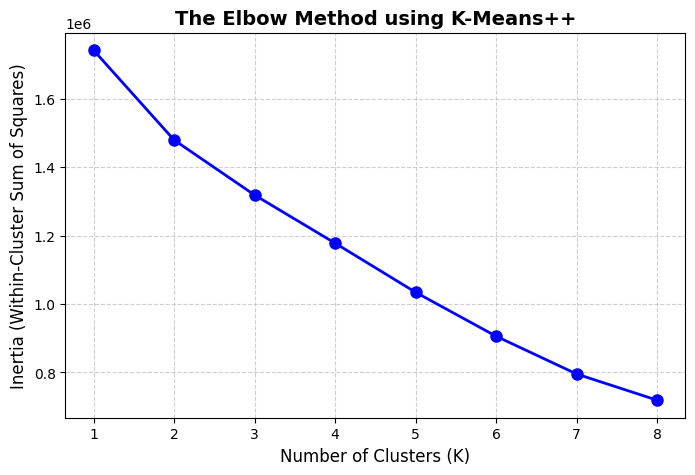

In [4]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

inertia_values = []
K_range = range(1, 9)

for k in K_range:
    # Sử dụng init='k-means++' tối ưu khởi tạo tâm cụm
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)
    print(f"K = {k} | Inertia = {kmeans.inertia_:.2f}")

# Vẽ biểu đồ Elbow
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia_values, marker='o', linestyle='-', color='b', linewidth=2, markersize=8)
plt.title('The Elbow Method using K-Means++', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (K)', fontsize=12)
plt.ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(K_range)
plt.show()

PHẦN 4: HUẤN LUYỆN K-MEANS++ CHÍNH THỨC & XUẤT KẾT QUẢ

In [5]:
# Chọn số cụm tối ưu (dựa trên biểu đồ Elbow ở Phần 3, thường chọn K = 3)
optimal_k = 3
print(f"=> Tiến hành phân cụm chính thức với số cụm: K = {optimal_k}")

kmeans_final = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
df_cluster["CLUSTER"] = kmeans_final.fit_predict(X_scaled)

# Tính giá trị trung bình các đặc trưng theo từng cụm
cluster_profile = df_cluster.groupby("CLUSTER")[feature_cols].mean().reset_index()
print("\n--- ĐẶC ĐIỂM TRUNG BÌNH CỦA TỪNG CỤM ---")
print(cluster_profile)

# Lưu file kết quả phân cụm ra Google Drive
output_file = os.path.join(folder_path, "customer_clusters_kmeans_plus.csv")
df_cluster.to_csv(output_file, index=False)
print(f"\nSaved thành công file tại: {output_file}")

=> Tiến hành phân cụm chính thức với số cụm: K = 3

--- ĐẶC ĐIỂM TRUNG BÌNH CỦA TỪNG CỤM ---
   CLUSTER     TRANS_SUM    TRANS_MEAN  TRANS_COUNT  CA_BALANCE_MEAN  \
0        0  2.176275e+07  1.193541e+06     4.415241     2.962772e+06   
1        1  0.000000e+00  0.000000e+00     0.000000     5.713524e+07   
2        2  5.076143e+09  1.856192e+08   117.250206     1.431499e+08   

   TD_BALANCE_MEAN  LOAN_AMOUNT_MEAN  
0     4.045660e+07      1.574525e+08  
1     0.000000e+00      1.638633e+11  
2     4.692756e+08      4.205995e+08  

Saved thành công file tại: /content/drive/MyDrive/kiemtrahocmay/customer_clusters_kmeans_plus.csv
